In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load abundance and map gene ID

In [2]:
hgnc = pd.read_csv(
    "../../data/HGNC/hgnc_complete_set.txt",
    sep="\t",
    low_memory=False,
)
hgnc = hgnc[hgnc["status"] == "Approved"]
approved_symbols = set(hgnc["symbol"])

with_entrez = hgnc.dropna(subset=["entrez_id"])
entrez2symbol = dict(
    zip(with_entrez["entrez_id"].astype(int), with_entrez["symbol"])
)

# retired symbol -> current symbol, keeping only names that resolve
# to a single approved gene
old2symbol = {}
for column in ["prev_symbol", "alias_symbol"]:
    for symbol, blob in zip(hgnc["symbol"], hgnc[column]):
        if not isinstance(blob, str):
            continue
        for old in blob.split("|"):
            old = old.strip()
            if old == "" or old in approved_symbols:
                continue
            old2symbol.setdefault(old, set()).add(symbol)
old2symbol = {
    old: next(iter(v)) for old, v in old2symbol.items() if len(v) == 1
}

In [3]:
df_abundance = pd.read_csv(
    "../../data/BioPlex/293T_HCT116_ProteomeComparison.tsv",
    sep="\t",
)

# Prioritize HGNC via Entrez ID, then old symbol, then keep as is
df_abundance["Gene"] = (
    df_abundance["GeneID"]
    .map(entrez2symbol)
    .fillna(df_abundance["Gene Symbol"].map(old2symbol))
    .fillna(df_abundance["Gene Symbol"])
)

### abundance of FAM126A/B

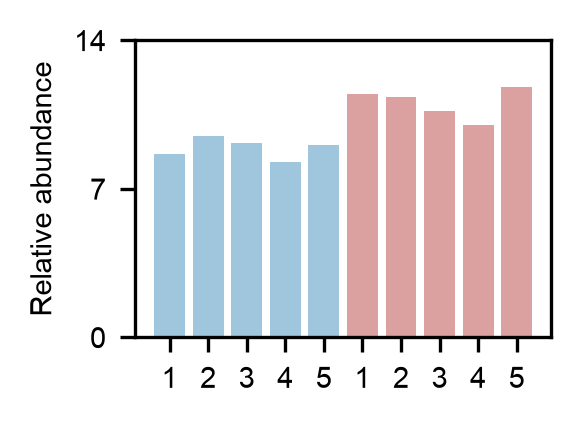

In [4]:
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, ax = plt.subplots(figsize=(1.54, 1.1), dpi=300)
fig.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.95)

plt.bar(
    x=list(range(10)),
    height=df_abundance.loc[
        df_abundance['Gene'] == "HYCC2",
        ["HCT1 scaled", "HCT2 scaled", "HCT3 scaled", "HCT4 scaled", "HCT5 scaled", "HEK1 scaled", "HEK2 scaled", "HEK3 scaled", "HEK4 scaled", "HEK5 scaled"]
    ].values[0],
    color=["#9fc6dd"]*5+["#dba1a1"]*5
)
plt.xticks(list(range(10)), [1,2,3,4,5,1,2,3,4,5])
plt.yticks([0,7,14])
plt.ylabel("Relative abundance")
plt.savefig("./figS16_abd_FAM126B.pdf", bbox_inches='tight', transparent=True)

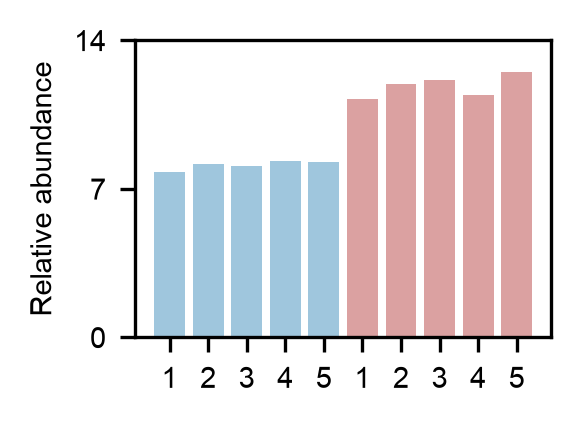

In [5]:
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, ax = plt.subplots(figsize=(1.54, 1.1), dpi=300)
fig.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.95)

plt.bar(
    x=list(range(10)),
    height=df_abundance.loc[
        df_abundance['Gene'] == "HYCC1",
        ["HCT1 scaled", "HCT2 scaled", "HCT3 scaled", "HCT4 scaled", "HCT5 scaled", "HEK1 scaled", "HEK2 scaled", "HEK3 scaled", "HEK4 scaled", "HEK5 scaled"]
    ].values[0],
    color=["#9fc6dd"]*5+["#dba1a1"]*5
)
plt.xticks(list(range(10)), [1,2,3,4,5,1,2,3,4,5])
plt.yticks([0,7,14])
plt.ylabel("Relative abundance")
plt.savefig("./figS16_abd_FAM126A.pdf", bbox_inches='tight', transparent=True)

### MS partner

In [6]:
AP_293 = pd.read_csv("../../result/HEK293T_HCT116/ppi/FromRaw_BioPlex_HEK293T.ppi", sep="\t", header=None)
AP_116 = pd.read_csv("../../result/HEK293T_HCT116/ppi/FromRaw_BioPlex_HCT116.ppi", sep="\t", header=None)
SEC_293 = pd.read_csv("../../result/HEK293T_HCT116/ppi/FromRaw_SECMX_HEK293T.ppi", sep="\t", header=None)
SEC_116 = pd.read_csv("../../result/HEK293T_HCT116/ppi/FromRaw_SECMX_HCT116.ppi", sep="\t", header=None)

print(AP_116[(AP_116[0].str.split("__", expand=True) == "HYCC2").any(axis=1)])

print(AP_293[(AP_293[0].str.split("__", expand=True) == "HYCC2").any(axis=1)])

print(SEC_116[(SEC_116[0].str.split("__", expand=True) == "HYCC2").any(axis=1)])

print(SEC_293[(SEC_293[0].str.split("__", expand=True) == "HYCC2").any(axis=1)])

                   0         1
50682  CIMIP5__HYCC2  0.927765
                  0    1
1669  CIMIP5__HYCC2  1.0
Empty DataFrame
Columns: [0, 1]
Index: []
Empty DataFrame
Columns: [0, 1]
Index: []


### promerge partner from emb

In [7]:
emb_293 = pd.read_csv("../../result/HEK293T_HCT116/ppi/promergeclub_HCT116anchor_HEK293T.ppi.Percent1", sep="\t", header=None)
score = emb_293[1].values
emb_293 = emb_293[0].str.split("__", expand=True)
emb_293[2] = score
emb_293_sub = emb_293[(emb_293[0] == "HYCC2") | (emb_293[1] == "HYCC2")]

emb_116 = pd.read_csv("../../result/HEK293T_HCT116/ppi/promergeclub_HCT116anchor_HCT116.ppi.Percent1", sep="\t", header=None)
score = emb_116[1].values
emb_116 = emb_116[0].str.split("__", expand=True)
emb_116[2] = score
emb_116_sub = emb_116[(emb_116[0] == "HYCC2") | (emb_116[1] == "HYCC2")]

emb_116_sub = emb_116_sub.iloc[:12]
emb_293_sub = emb_293_sub.iloc[:12]

In [8]:
# HCT116 unique
print(set.union(set(emb_116_sub[0]), set(emb_116_sub[1])) - set.union(set(emb_293_sub[0]), set(emb_293_sub[1])))
# HEK293T unique
print(set.union(set(emb_293_sub[0]), set(emb_293_sub[1])) - set.union(set(emb_116_sub[0]), set(emb_116_sub[1])))
# Both share
print(set.union(set(emb_293_sub[0]), set(emb_293_sub[1])).intersection(set.union(set(emb_116_sub[0]), set(emb_116_sub[1]))))

{'RECK', 'PDE9A', 'GNAZ', 'TXN2', 'FMNL2', 'AVPI1', 'SH3RF2', 'CFAP74', 'CRIP2'}
{'DCAF10', 'TTC7B', 'PI4KA', 'GFOD2', 'FOXE1', 'NKIRAS2', 'RNF214', 'CCDC50', 'TIMD4'}
{'HYCC2', 'CIMIP5', 'NECAB2', 'GLB1L3'}


### co-abundance (correlation)

In [9]:
abd = df_abundance[df_abundance['Gene'].isin(['HYCC2', 'HYCC1', 'TTC7B', 'PI4KA', 'TXN2', 'RECK'])]
abd = abd[abd['Protein Id'] != "tr|H7C0W7|H7C0W7_HUMAN"] #remove non canonical one
abd = abd.set_index("Gene")

In [10]:
corr1 = abd.iloc[:, 3:8].T.corr().loc["HYCC2", ['HYCC1', 'TTC7B', 'PI4KA', 'TXN2', 'RECK']]
corr2 = abd.iloc[:, 8:13].T.corr().loc["HYCC2", ['HYCC1', 'TTC7B', 'PI4KA', 'TXN2', 'RECK']]

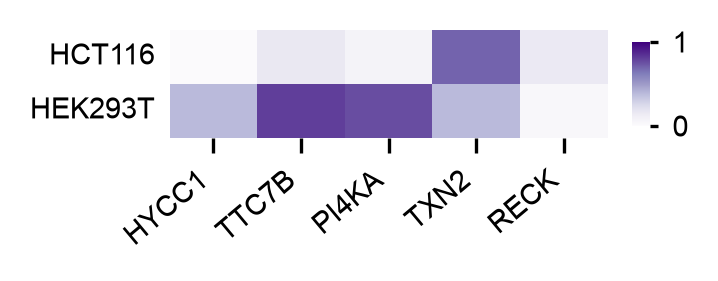

In [11]:
plt.style.use("/home/jig049/misc/style.mplstyle")

data = np.array([
    corr1.abs().values,
    corr2.abs().values
])

fig, ax = plt.subplots(figsize=(2, 0.4), dpi=300)
fig.subplots_adjust(left=0.05, right=0.78, bottom=0.05, top=0.95)

cax = fig.add_axes([0.82, 0.15, 0.03, 0.70])

sns.heatmap(
    data,
    ax=ax,
    cmap="Purples",
    vmin=0,
    vmax=1,
    xticklabels=["HYCC1", "TTC7B", "PI4KA", "TXN2", "RECK"],
    yticklabels=["HCT116", "HEK293T"],
    cbar=True,
    cbar_ax=cax,
    cbar_kws={"ticks": [0, 1]},
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=40,
    ha="right",
    va="top",
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
)

ax.tick_params(axis="y", length=0)

# Colorbar formatting
cax.tick_params(axis="y", length=2)
cax.set_yticks([0, 1])

plt.savefig("./fig3_heatmap_abundance.pdf", bbox_inches='tight', transparent=True)

### pert response

In [12]:
pert1 = pd.read_csv("../../data/Xaira/HCT116_pseudobulk_mean_AllPertsByExpressedGenes.tsv", sep="\t", index_col=0)
pert2 = pd.read_csv("../../data/Xaira/HEK293T_pseudobulk_mean_AllPertsByExpressedGenes.tsv", sep="\t", index_col=0)

In [13]:
p1 = pert1.loc["HYCC2", ['HYCC1', 'TTC7B', 'PI4KA', 'TXN2', 'RECK']]
p2 = pert2.loc["HYCC2", ['HYCC1', 'TTC7B', 'PI4KA', 'TXN2', 'RECK']]

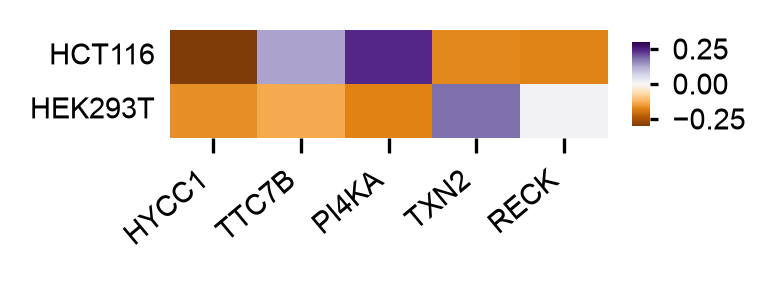

In [14]:
plt.style.use("/home/jig049/misc/style.mplstyle")

data = np.array([
    p1.values,
    p2.values
])

fig, ax = plt.subplots(figsize=(2, 0.4), dpi=300)
fig.subplots_adjust(left=0.05, right=0.78, bottom=0.05, top=0.95)

# Colorbar axes: [left, bottom, width, height]
cax = fig.add_axes([0.82, 0.15, 0.03, 0.70])

sns.heatmap(
    data,
    ax=ax,
    cmap="PuOr",
    vmin=-0.3, vmax=0.3, center=0,
    xticklabels=["HYCC1", "TTC7B", "PI4KA", "TXN2", "RECK"],
    yticklabels=["HCT116", "HEK293T"],
    cbar=True,
    cbar_ax=cax,
    cbar_kws={"ticks": [-0.25, 0, 0.25]},
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=40,
    ha="right",
    va="top",
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
)

ax.tick_params(axis="y", length=0)

# Colorbar formatting
cax.set_yticks([-0.25, 0, 0.25])
cax.tick_params(axis="y", length=2)

plt.savefig("./fig3_heatmap_pert.pdf", bbox_inches='tight', transparent=True)